# Looply | 재분석 노트북 (pandas · NumPy · SciPy · scikit-learn)

원자료(7개 영향범주 전부)에서 다시 시작해서, **빠지는 값이 어디에 얼마나 있는지**부터 확인하고 분석한 과정입니다. 웹앱 리포트의 숫자는 모두 이 흐름(`analysis/reanalysis.py`)에서 나옵니다.

1. 어디에 값이 있고 비어 있는지 (오존층영향·광화학스모그를 왜 이렇게 다뤘는지)
2. 분석 범위와, 빠진 항목이 한쪽으로 쏠리는지
3. 묶을 때 쓸 영향과 무리 수(k)를 **미리 정한 규칙**으로 고르기
4. 무리 해석, 영향을 바꿨을 때의 흔들림
5. 영향끼리의 관계(순위 상관), 탄소 순위와 다른 영향 순위가 크게 다른 원료
6. 웹앱(JavaScript) 결과와 비교

> 군집은 비슷한 계수를 가진 항목을 묶은 **탐색용 분류**이며 환경성능 순위나 공식 분류가 아닙니다.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, sklearn, scipy
from pathlib import Path
from scipy.stats import spearmanr
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score, adjusted_rand_score
plt.rcParams["font.family"] = ["Malgun Gothic", "AppleGothic", "NanumGothic", "Noto Sans CJK KR", "sans-serif"]
plt.rcParams["axes.unicode_minus"] = False
DATA = Path("../data/lca_factors_clean.csv")
if not DATA.exists(): DATA = Path("data/lca_factors_clean.csv")
print("scikit-learn", sklearn.__version__, "| scipy", scipy.__version__)

scikit-learn 1.9.1 | scipy 1.18.1


## 1. 값이 어디에 있고 어디가 비어 있나

`해당없음`은 0이 아니라 **값이 없다**는 뜻이라서 빈 값(NaN)으로 두었습니다(정제 파일에는 이미 빈 칸으로 저장).

In [2]:
df = pd.read_csv(DATA, encoding="utf-8-sig")
df["단위"] = df["단위"].str.strip()
COLS = list(df.columns[4:])
print(df.shape, "| 0 이하 값:", int((df[COLS] <= 0).sum().sum()))
cov = df.groupby("대분류")[COLS].agg(lambda s: s.notna().mean()*100).round(0)
cov.insert(0, "항목수", df.groupby("대분류").size())
cov

(398, 11) | 0 이하 값: 0


,항목수,자원발자국(kg Sb eq),탄소발자국(kg CO2 eq),오존층영향(kg CFC11 eq),산성비(kg SO2 eq),부영양화(kg PO43- eq),광화학스모그(kg C2H4 eq),물소모계수(m3 H2O eq)
대분류,,,,,,,,
수송,10,100.0,100.0,50.0,60.0,50.0,70.0,70.0
연료원별 사용,113,0.0,100.0,0.0,0.0,0.0,0.0,0.0
원료 및 에너지 생산,198,96.0,100.0,7.0,92.0,83.0,78.0,88.0
폐기물 처리,32,69.0,100.0,3.0,69.0,66.0,75.0,59.0
화학반응공정,45,0.0,100.0,0.0,0.0,0.0,0.0,0.0


**읽는 법:** 연료원별 사용·화학반응공정(158개)은 탄소발자국만 있습니다. 오존층영향은 어느 단계든 거의 비어 있어서(원료 단계 93% 결측) 분석에서 제외하고 계산기에서만 값이 있는 항목을 보여 줍니다. 광화학스모그는 원료 단계에서 78%가 차 있어 **분석에 쓸 수 있는 영향**이지만, 85% 기준에는 못 미쳐 묶을 때 기본값으로는 쓰지 않았습니다(웹앱에서 직접 체크 가능).

## 2. 분석 범위와 빠진 항목의 쏠림

단위가 다르면 한 줄로 비교할 수 없으므로 `원료 및 에너지 생산` · `kg`만 씁니다. 수돗물·공업용수(구분=수자원)는 재료가 아니라 물 자체라 값이 1000배 이상 작아 따로 둡니다.

In [3]:
KEY = dict(zip(["자원","탄소","오존","산성","부영","스모그","물"], COLS))
base = df[(df["대분류"]=="원료 및 에너지 생산") & (df["단위"]=="kg")]
print("원료·kg:", len(base), "| 수자원 제외 후:", (base["구분"]!="수자원").sum())
base = base[base["구분"]!="수자원"].copy()
cover = {k: base[c].notna().mean() for k, c in KEY.items()}
print({k: f"{v*100:.0f}%" for k, v in cover.items()})
FEAT = [k for k, v in cover.items() if v >= 0.85]          # 규칙: 85% 이상 채워진 영향만 묶는 데 사용
print("묶는 데 쓴 영향:", FEAT)
fc = [KEY[k] for k in FEAT]
d = base.dropna(subset=fc).copy()
print("분석 항목:", len(d), "/", len(base))
t = pd.DataFrame({"전체": base["구분"].value_counts(), "분석에 포함": d["구분"].value_counts()}).fillna(0).astype(int)
t["빠진 비율(%)"] = ((t["전체"]-t["분석에 포함"])/t["전체"]*100).round(0).astype(int)
t.sort_values("빠진 비율(%)", ascending=False)

원료·kg: 189 | 수자원 제외 후: 187
{'자원': '96%', '탄소': '100%', '오존': '7%', '산성': '91%', '부영': '85%', '스모그': '78%', '물': '87%'}
묶는 데 쓴 영향: ['자원', '탄소', '산성', '부영', '물']
분석 항목: 142 / 187


,전체,분석에 포함,빠진 비율(%)
구분,,,
에너지,9,2,78
건축자재,23,10,57
고무,4,3,25
기타,17,13,24
금속,15,12,20
기초화학물질,79,63,20
전기부품,16,15,6
펄프 및 종이,6,6,0
플라스틱,18,18,0


**읽는 법:** 빠진 항목은 고르게 흩어져 있지 않습니다. 에너지(78%)와 건축자재(57%)가 많이 빠졌으므로, 아래 군집 결과는 이 구분에 대해서는 대표성이 낮습니다. 웹앱은 영향 선택에 따라 이 비율을 바로 보여 줍니다.

## 3. 무리 수(k) 고르기: 미리 정한 규칙

로그 변환 → 표준화 후 KMeans. 각 k마다 시작 위치를 바꿔 20번 돌려서 결과가 얼마나 같은지(ARI)도 확인합니다.

**규칙(결과를 보기 전에 정함):** ① 안정성 0.95 이상 ② 가장 작은 무리가 전체의 10% 이상 ③ 둘을 통과한 k 중 Davies-Bouldin이 가장 낮은 것.

In [4]:
X = StandardScaler().fit_transform(np.log10(d[fc].values))
rows, models = [], {}
for k in range(2, 7):
    ms = [KMeans(k, n_init=10, random_state=s).fit(X) for s in range(20)]
    m = min(ms, key=lambda z: z.inertia_); models[k] = m
    rows.append({"k": k, "silhouette": silhouette_score(X, m.labels_), "davies_bouldin": davies_bouldin_score(X, m.labels_),
                 "안정성(ARI)": np.mean([adjusted_rand_score(m.labels_, z.labels_) for z in ms]),
                 "크기": sorted(np.bincount(m.labels_).tolist(), reverse=True), "최소군집": np.bincount(m.labels_).min()})
sc = pd.DataFrame(rows).set_index("k").round(3)
ok = sc[(sc["안정성(ARI)"] >= 0.95) & (sc["최소군집"] >= 0.10*len(d))]
K = int(ok["davies_bouldin"].idxmin())
print("규칙을 통과한 k:", ok.index.tolist(), "→ 선택 k =", K)
sc

규칙을 통과한 k: [2, 3] → 선택 k = 3


,silhouette,davies_bouldin,안정성(ARI),크기,최소군집
k,,,,,
2,0.329,1.192,1.000,"[86, 56]",56
3,0.327,1.146,1.000,"[85, 40, 17]",17
4,0.300,1.129,0.941,"[64, 37, 24, 17]",17
5,0.309,1.057,0.958,"[55, 36, 24, 23, 4]",4
6,0.315,1.125,0.917,"[53, 36, 22, 14, 13, 4]",4


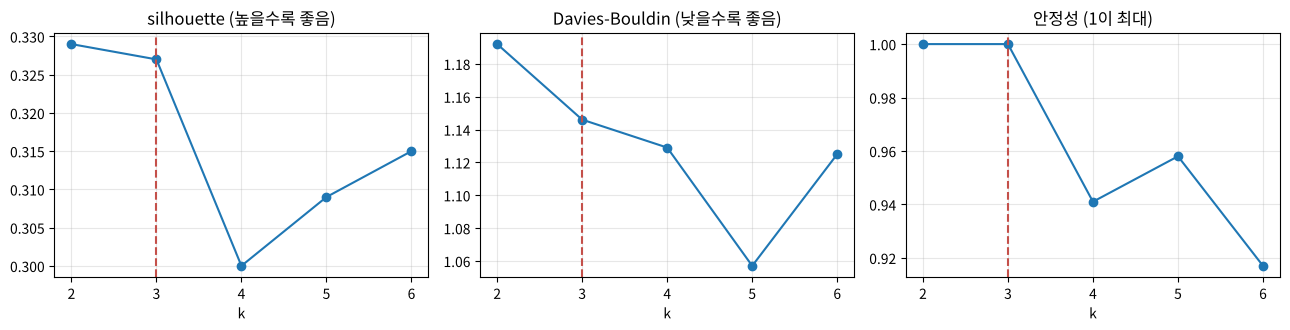

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.4))
for a, col, ttl in zip(ax, ["silhouette", "davies_bouldin", "안정성(ARI)"], ["silhouette (높을수록 좋음)", "Davies-Bouldin (낮을수록 좋음)", "안정성 (1이 최대)"]):
    a.plot(sc.index, sc[col], marker="o"); a.axvline(K, color="#c4504a", ls="--"); a.set_title(ttl); a.set_xlabel("k"); a.grid(alpha=.3)
plt.tight_layout(); plt.show()

**읽는 법:** k=2와 k=3의 실루엣은 0.329와 0.327로 사실상 같습니다. 규칙이 k=3을 골랐고, 3단계가 읽기 쉽다는 점도 반영했습니다. 그러나 실루엣이 0.33 수준이라 **무리 사이 경계는 흐릿합니다**(0.5 이상이어야 뚜렷하다고 봅니다).

## 4. 무리 해석

무리 번호는 탄소 중앙값이 작은 순서입니다(순위가 아니라 식별 번호).

In [6]:
d["군집"] = pd.Series(models[K].labels_, index=d.index)
rank = {c: i+1 for i, c in enumerate(d.groupby("군집")[KEY["탄소"]].median().sort_values().index)}
d["군집"] = d["군집"].map(rank)
overall = d[fc].median()
ratio = d.groupby("군집")[fc].median().div(overall).round(2)
ratio.columns = [c.split("(")[0] for c in ratio.columns]
ratio.insert(0, "항목수", d.groupby("군집").size())
print("전체 중앙값 대비 배수:")
ratio

전체 중앙값 대비 배수:


,항목수,자원발자국,탄소발자국,산성비,부영양화,물소모계수
군집,,,,,,
1,40,0.16,0.37,0.24,0.28,0.46
2,85,1.20,1.15,1.24,1.56,1.50
3,17,2.99,4.27,55.75,47.19,0.90


In [7]:
print(pd.crosstab(d["구분"], d["군집"]).to_string())
big = pd.crosstab(d["구분"], d["군집"]); big = big[big.sum(axis=1) >= 8]
print("\n구분별로 가장 많은 한 무리에 속한 비율(%):"); print((big.max(axis=1)/big.sum(axis=1)*100).round(0).to_string())
print("\n3번 무리 항목:", d[d["군집"]==3]["원료_에너지"].tolist())

군집        1   2  3
구분                
건축자재      7   2  1
고무        0   3  0
금속        3   7  2
기초화학물질   17  38  8
기타        8   5  0
에너지       2   0  0
전기부품      0   9  6
펄프 및 종이   2   4  0
플라스틱      1  17  0

구분별로 가장 많은 한 무리에 속한 비율(%):
구분
건축자재      70.0
금속        58.0
기초화학물질    60.0
기타        62.0
전기부품      60.0
플라스틱      94.0

3번 무리 항목: ['유리면', '니켈', '아연', '부탄', '산화아연', '산화철', '에피클로로히드린', '카프로락탐', '폴리아마이드6', '폴리아마이드66', '폴리우레탄', '경성 인쇄회로기판', '리드선 SDA 0.5mm', '리드선 SDA 0.6mm', '리드선 TDA 0.6mm', '무연솔더', '연성 인쇄회로기판']


**읽는 법:** 1번은 전반적으로 작은 무리, 2번은 전체 중앙값과 비슷한 중간 무리, 3번은 **산성비와 부영양화가 중앙값의 50배 안팎**으로 유난히 큰 소수 무리입니다(금속류, 나일론 계열, 전자부품이 많이 들어 있어요; 왜 큰지는 이 표만으로는 알 수 없습니다). 또 기초화학물질 63개는 세 무리에 모두 흩어져 있어, **재료 구분 이름만으로는 영향 크기를 짐작하기 어렵습니다.**

### 묶는 영향을 바꾸면 결과가 얼마나 달라지나

In [8]:
def labels_for(cols):
    dd = base.dropna(subset=[KEY[c] for c in cols])
    Z = StandardScaler().fit_transform(np.log10(dd[[KEY[c] for c in cols]].values))
    m = min([KMeans(K, n_init=10, random_state=s).fit(Z) for s in range(10)], key=lambda z: z.inertia_)
    return pd.Series(m.labels_, index=dd.index)
res = []
for name, cs in {"핵심 3개(탄소·자원·산성)": ["탄소","자원","산성"], "5개(기본)": FEAT, "6개(+광화학스모그)": ["탄소","자원","산성","부영","물","스모그"]}.items():
    lab = labels_for(cs); common = lab.index.intersection(d.index)
    res.append({"영향 구성": name, "분석 항목": len(lab), "기본과 겹치는 항목": len(common), "일치도(ARI)": round(adjusted_rand_score(d.loc[common,"군집"], lab.loc[common]), 2)})
pd.DataFrame(res)

,영향 구성,분석 항목,기본과 겹치는 항목,일치도(ARI)
0,핵심 3개(탄소·자원·산성),171,142,0.55
1,5개(기본),142,142,1.00
2,6개(+광화학스모그),130,130,0.69


**읽는 법:** 영향 구성을 바꾸면 일치도가 0.55~0.69로 떨어집니다(1이면 완전히 같음). 그래서 군집 결과는 "어떤 원료끼리 비슷해 보이는지 살펴보는 **참고용**"으로만 씁니다.

## 5. 영향끼리의 관계, 탄소만 보면 놓치는 것

순위 상관(Spearman)은 두 영향의 순위가 함께 오르내리는 정도입니다. 값이 있는 쌍만 비교하고, 개수(n)를 함께 봅니다.

In [9]:
names = [k for k in KEY if k != "오존"]
rho = pd.DataFrame(index=names, columns=names, dtype=float); nn = rho.copy()
for a in names:
    for b in names:
        s = base[[KEY[a], KEY[b]]].dropna(); nn.loc[a, b] = len(s)
        rho.loc[a, b] = 1.0 if a == b else spearmanr(s.iloc[:,0], s.iloc[:,1])[0]
print(rho.round(2).to_string()); print("\n비교한 개수:"); print(nn.astype(int).to_string())

       자원    탄소    산성    부영   스모그     물
자원   1.00  0.74  0.76  0.65  0.60  0.26
탄소   0.74  1.00  0.81  0.70  0.54  0.32
산성   0.76  0.81  1.00  0.83  0.61  0.23
부영   0.65  0.70  0.83  1.00  0.53  0.23
스모그  0.60  0.54  0.61  0.53  1.00  0.09
물    0.26  0.32  0.23  0.23  0.09  1.00

비교한 개수:
      자원   탄소   산성   부영  스모그    물
자원   180  180  171  159  146  161
탄소   180  187  171  159  146  163
산성   171  171  171  153  140  152
부영   159  159  153  159  143  148
스모그  146  146  140  143  146  139
물    161  163  152  148  139  163


In [10]:
pct = pd.DataFrame({k: base[KEY[k]].rank(pct=True)*100 for k in names})
hid = []
for idx, r in pct.iterrows():
    cand = [(k, r[k]-r["탄소"]) for k in names if k != "탄소" and pd.notna(r[k])]
    if cand:
        k, diff = max(cand, key=lambda x: x[1])
        if diff >= 40: hid.append((base.loc[idx,"원료_에너지"], base.loc[idx,"구분"], round(r["탄소"]), k, round(r[k]), round(diff)))
hid = pd.DataFrame(hid, columns=["원료","구분","탄소 순위(%)","더 높은 영향","그 영향 순위(%)","차이"]).sort_values("차이", ascending=False)
print("탄소 순위보다 다른 영향 순위가 40점 이상 높은 원료:", len(hid), "/", len(base))
hid.head(10)

탄소 순위보다 다른 영향 순위가 40점 이상 높은 원료: 25 / 187


,원료,구분,탄소 순위(%),더 높은 영향,그 영향 순위(%),차이
20,골판지,펄프 및 종이,7,물,95,88
21,트랜지스터,전기부품,10,물,94,85
0,유리면,건축자재,17,산성,100,83
10,염화칼륨,기초화학물질,5,물,83,79
23,재생 활성탄,기타,25,부영,96,71
7,암모니아,기초화학물질,28,부영,93,65
12,질산,기초화학물질,24,부영,88,65
8,염산(35%),기초화학물질,18,물,79,61
4,가성칼륨,기초화학물질,29,물,84,55
5,나프타,기초화학물질,9,자원,62,53


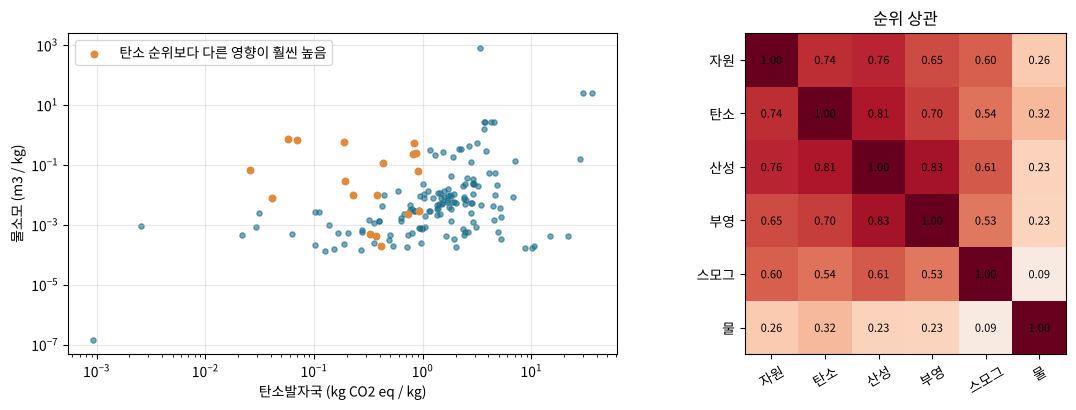

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
c, w = KEY["탄소"], KEY["물"]; p = base.dropna(subset=[c, w])
ax[0].scatter(p[c], p[w], s=14, alpha=.6, color="#1f6f8b")
h = p[p["원료_에너지"].isin(hid["원료"])]; ax[0].scatter(h[c], h[w], s=22, color="#e08a3c", label="탄소 순위보다 다른 영향이 훨씬 높음")
ax[0].set_xscale("log"); ax[0].set_yscale("log"); ax[0].set_xlabel("탄소발자국 (kg CO2 eq / kg)"); ax[0].set_ylabel("물소모 (m3 / kg)"); ax[0].legend(); ax[0].grid(alpha=.3)
im = ax[1].imshow(rho.values, cmap="RdBu_r", vmin=-1, vmax=1); ax[1].set_xticks(range(len(names))); ax[1].set_xticklabels(names, rotation=30); ax[1].set_yticks(range(len(names))); ax[1].set_yticklabels(names)
for i in range(len(names)):
    for j in range(len(names)): ax[1].text(j, i, f"{rho.values[i,j]:.2f}", ha="center", va="center", fontsize=8)
ax[1].set_title("순위 상관"); plt.tight_layout(); plt.show()

**읽는 법:** 탄소는 자원·산성·부영양화와 함께 움직이는 편(0.7~0.8)이지만 **물소모와는 약합니다(0.3)**. 골판지·트랜지스터·유리면처럼 탄소만 보면 작아 보이지만 물소모나 산성비는 큰 원료가 있습니다. 순위는 같은 단위(1kg)당 계수를 비교한 값이며 쓰임새가 다른 원료의 우열이 아닙니다.

## 6. 웹앱(JavaScript) 결과와 비교

`data/web_kmeans_k3.csv`는 웹앱의 "묶어 보기" 탭 기본 설정(5개 영향, k=3)에서 나온 무리 번호입니다.

In [12]:
web = pd.read_csv("../data/web_kmeans_k3.csv", encoding="utf-8-sig").set_index("행번호")["웹군집"]
both = d["군집"].to_frame("scikit-learn").join(web.rename("웹(JS)"), how="inner")
print("비교 항목:", len(both), "| ARI:", round(adjusted_rand_score(both["scikit-learn"], both["웹(JS)"]), 3),
      "| 같은 번호:", int((both["scikit-learn"]==both["웹(JS)"]).sum()), "/", len(both))

비교 항목: 142 | ARI: 1.0 | 같은 번호: 142 / 142


**한계**

- 계수는 2021년 기준 평균값이며 인증 값이 아닙니다. 원자료 이용 조건은 별도 확인이 필요합니다.
- KMeans는 시작 위치와 이상값에 영향을 받습니다. k=3·5개 영향에서는 웹과 scikit-learn이 일치했지만, 다른 k에서는 소폭 다를 수 있습니다(예: k=5 실루엣 웹 0.307 vs scikit-learn 0.309).
- 군집 결과는 영향 구성에 민감하므로 참고용입니다.